In [11]:
import pandas as pd
import numpy as np


In [12]:
!curl -L -o data.csv https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  620k  100  620k    0     0  5017k      0 --:--:-- --:--:-- --:--:-- 5043k


In [13]:

df = pd.read_csv("data.csv")
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

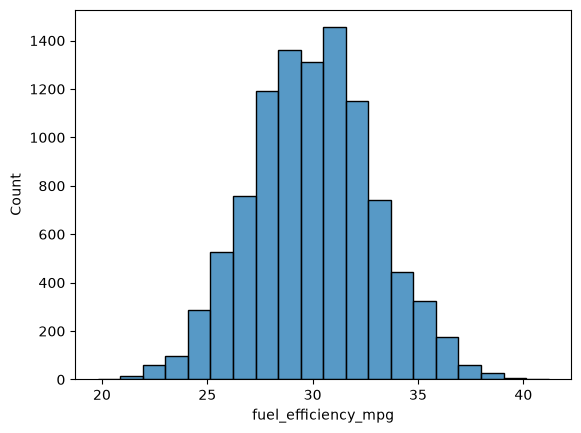

In [15]:
sns.histplot(df.fuel_efficiency_mpg, bins=20)

In [16]:
##Look at the fuel_efficiency_mpg variable. Does it have a long tail?
# no long tail. its a clean normal bell curve

In [17]:

df.isnull().sum()


model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [18]:
df.horsepower.median()

np.float64(254.0)

In [19]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [20]:
n, n_val, n_test, n_train

(10000, 2000, 2000, 6000)

In [29]:

y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
y_test = np.log1p(df_test.fuel_efficiency_mpg.values)

In [30]:
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [23]:
# linear regression without regularization

def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [22]:
#linear regression with regularization

def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [24]:
df.dtypes

model_year               int64
origin                     str
fuel_type                  str
drivetrain                 str
num_doors                int64
engine_displacement      int64
num_cylinders            int64
horsepower             float64
vehicle_weight           int64
acceleration           float64
fuel_efficiency_mpg    float64
dtype: object

In [61]:

base = ['model_year', 'num_doors', 'engine_displacement', 'num_cylinders','horsepower','vehicle_weight','acceleration']

def prepare_X(df):
    df = df.copy()
    features = base.copy()

    #df.horsepower.fillna(0)

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X


In [56]:
def rmse(y,y_pred):
    se=(y-y_pred)**2
    mse=se.mean()
    return np.sqrt(mse)

In [33]:
X_train = prepare_X(df_train)
w0,w=train_linear_regression(X_train,y_train)
X_val = prepare_X(df_val)
y_pred=w0+X_val.dot(w)
rmse(y_val,y_pred)

np.float64(0.07146281206179825)

In [45]:

def prepare_X(df):
    df = df.copy()
    features = base.copy()

    #df.horsepower.fillna(0)

    mean_horsepower = df.horsepower.mean()
    mean_acceleration = df.acceleration.mean()
    
    df['horsepower']=df.horsepower.fillna(mean_horsepower)
    df['acceleration']=df.horsepower.fillna(mean_acceleration)

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X


In [43]:
X_train = prepare_X(df_train)
w0,w=train_linear_regression(X_train,y_train)
X_val = prepare_X(df_val)
y_pred=w0+X_val.dot(w)
rmse(y_val,y_pred)

np.float64(0.07134659716508095)

In [46]:
X_train = prepare_X(df_train)
w0,w=train_linear_regression_reg(X_train,y_train)
X_val = prepare_X(df_val)
y_pred=w0+X_val.dot(w)
rmse(y_val,y_pred)

np.float64(0.07134907714835328)

In [50]:
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    X_train = prepare_X(df_train)
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)

    X_val = prepare_X(df_val)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)

    print(r, w0, score)


#best is r = 0, with the smallest rmse

0 -2.546274729176335 0.07146281206179825
0.01 -2.4535377380180527 0.0714669738733303
0.1 -1.8478412746510078 0.07161962001625144
1 -0.532722866221941 0.07269122710721694
5 -0.12796060944927093 0.07321980666554302
10 -0.0656284740093466 0.07330914406464778
100 -0.006717087959638425 0.07339293150022085


In [62]:
rmse_ = []

for s in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:

    np.random.seed(s)
    idx = np.arange(n)
    np.random.shuffle(idx)
    
    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

        
    y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
    y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
    y_test = np.log1p(df_test.fuel_efficiency_mpg.values)

    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']
    
    X_train = prepare_X(df_train)
    w0,w=train_linear_regression(X_train,y_train)
    X_val = prepare_X(df_val)
    y_pred=w0+X_val.dot(w)
    rmse_score = rmse(y_val,y_pred)
    rmse_.append(rmse_score)

        

In [63]:
print(round(np.std(rmse_), 3))

0.001
